# به نام خدا

In [1]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd

In [2]:
df = sns.load_dataset('titanic')

In [3]:
df.dtypes

survived          int64
pclass            int64
sex              object
age             float64
sibsp             int64
parch             int64
fare            float64
embarked         object
class          category
who              object
adult_male         bool
deck           category
embark_town      object
alive            object
alone              bool
dtype: object

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   survived     891 non-null    int64   
 1   pclass       891 non-null    int64   
 2   sex          891 non-null    object  
 3   age          714 non-null    float64 
 4   sibsp        891 non-null    int64   
 5   parch        891 non-null    int64   
 6   fare         891 non-null    float64 
 7   embarked     889 non-null    object  
 8   class        891 non-null    category
 9   who          891 non-null    object  
 10  adult_male   891 non-null    bool    
 11  deck         203 non-null    category
 12  embark_town  889 non-null    object  
 13  alive        891 non-null    object  
 14  alone        891 non-null    bool    
dtypes: bool(2), category(2), float64(2), int64(4), object(5)
memory usage: 80.7+ KB


In [5]:
df

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
886,0,2,male,27.0,0,0,13.0000,S,Second,man,True,NaN,Southampton,no,True
887,1,1,female,19.0,0,0,30.0000,S,First,woman,False,B,Southampton,yes,True
888,0,3,female,NaN,1,2,23.4500,S,Third,woman,False,NaN,Southampton,no,False
889,1,1,male,26.0,0,0,30.0000,C,First,man,True,C,Cherbourg,yes,True


In [6]:
df.isna().sum()

survived         0
pclass           0
sex              0
age            177
sibsp            0
parch            0
fare             0
embarked         2
class            0
who              0
adult_male       0
deck           688
embark_town      2
alive            0
alone            0
dtype: int64

<div dir='rtl'>

- در مرحله اول که هنوز چیزی از داده نمیدونیم، تک تک ستون هارو شروع به آنالیز میکنیم.
- از plot های  **Figure-level** استفاده میکنم تا بتونم هردفعه نوعشون رو تغییر بدم.

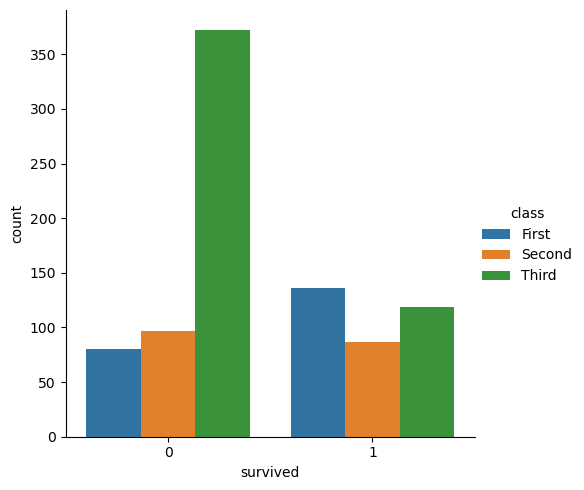

In [7]:
sns.catplot(
    data=df,
    x="survived",
    hue='class',
    kind='count'
)

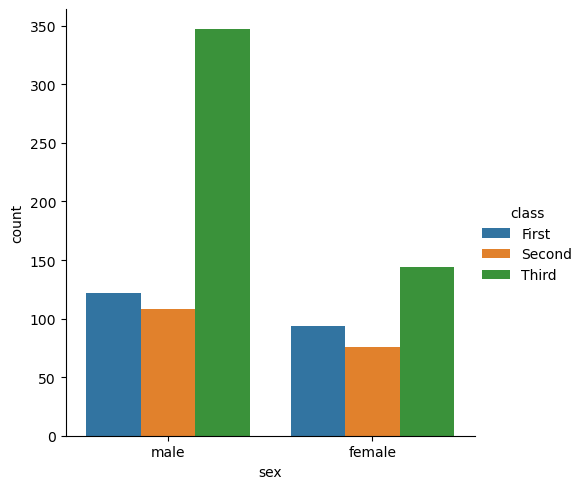

In [8]:
sns.catplot(
    data=df,
    x='sex',
    hue='class',
    kind='count'
)

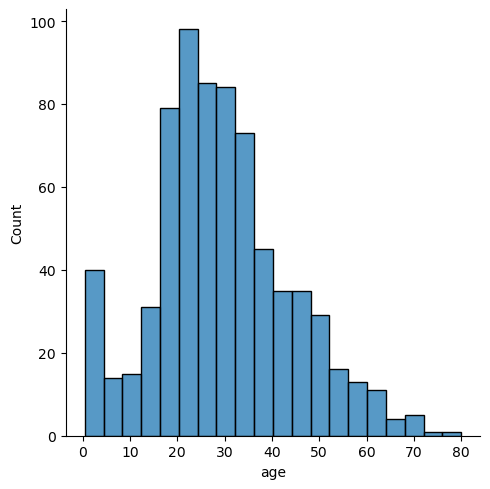

In [9]:
sns.displot(
    data=df,
    x='age'
)

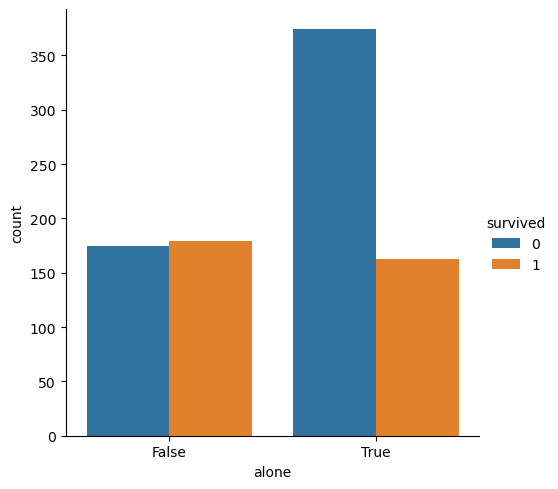

In [10]:
sns.catplot(
    data=df,
    x='alone',
    hue='survived',
    kind='count'
)

<div dir='rtl'>

- بیشتر افرادی که نجات پیداکردن تنها نبودن


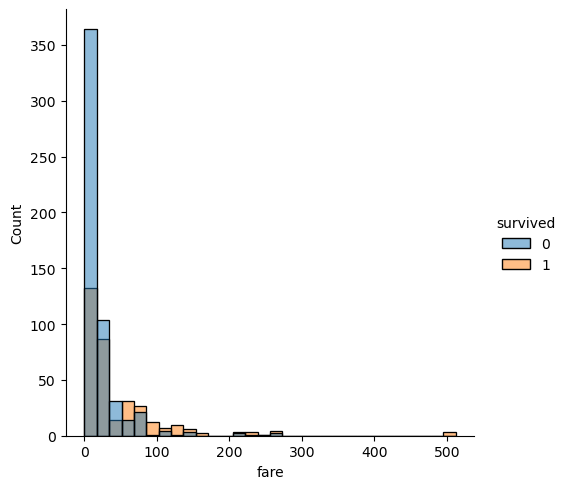

In [11]:
sns.displot(
    data=df,
    x='fare',
    hue='survived',
    bins=30
)


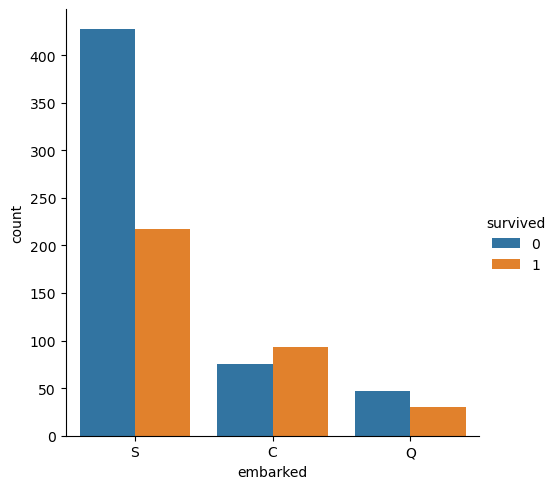

In [12]:
# از کدوم بندر سوار شدن
sns.catplot(
    data=df,
    x='embarked',
    hue='survived',
    kind='count'
)

In [13]:
# To ensure that `pclass` is the same as `class`
(df['class'].map({
    'First': 1,
    'Second': 2,
    'Third': 3,
}) == df['pclass']).all()

np.True_

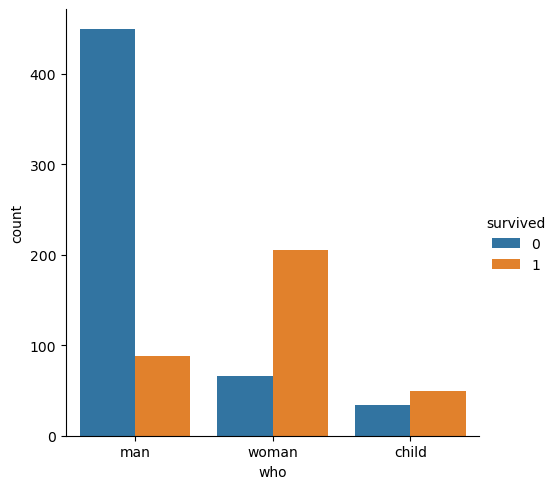

In [14]:
sns.catplot(
    data=df,
    x='who',
    hue='survived',
    kind='count'
)

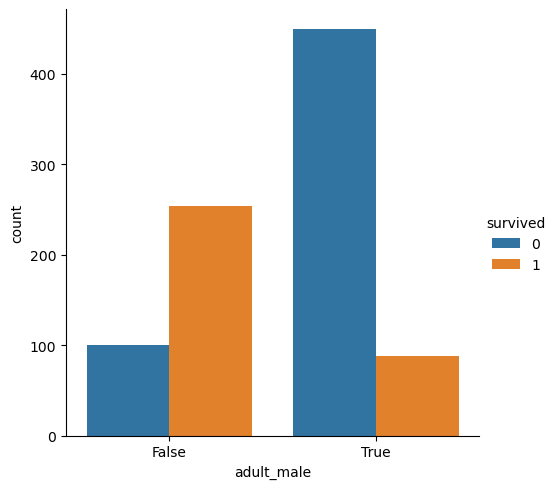

In [15]:
sns.catplot(
    data=df,
    x='adult_male',
    hue='survived',
    kind='count'
)

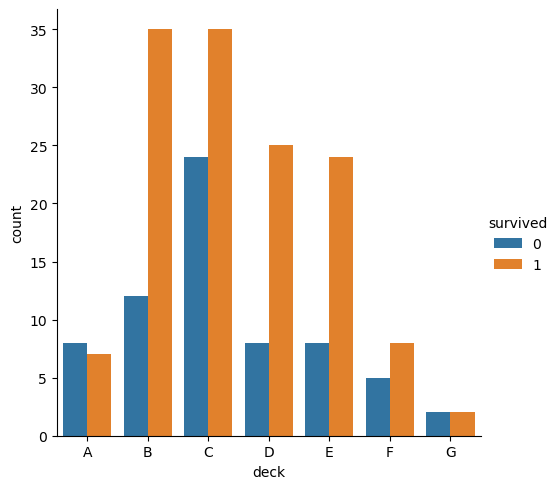

In [16]:
# عرشه(طبقه)کشتی
sns.catplot(
    data=df,
    x='deck',
    hue='survived',
    kind='count'
)

<div dir='rtl'>

هرچه class بالاتر احتمال زنده بودندت بیشتر؛ اما این نمودار این رو نشون نمیده و دلیلش به خاطر NaN بودن زیاده ستون deck هستش.

In [17]:
# To ensure that `alive` is the same as `survived`
(df.alive.map({
    'yes': 1,
    'no': 0,
}) == df.survived).all()

np.True_

<div dir='rtl'>

تا به اینجا یک دید کلی و خوبی به داده پیدا کردیم

حالا از این به بعد می خوایم رابطه چنتا feature رو باهم ببینیم.

In [21]:
df['alone'] = df['alone'].map({
    True : 1,
    False : 0
})

df['who'] = df['who'].map({
    'man':1,
    'woman':2,
    'child':3
})
df_numerical = df.select_dtypes(include=['int64', 'float64'])

<Axes: >

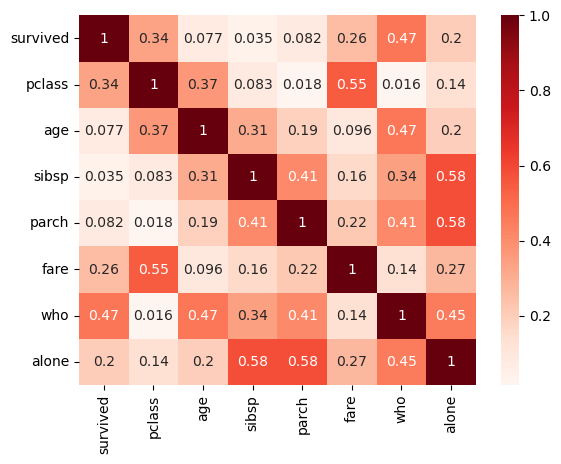

In [25]:
sns.heatmap(
    abs(df_numerical.corr()),
    annot=True,
    cmap='Reds'
)